<a href="https://colab.research.google.com/github/Sara200413/Apprentissage-Supervise-TP1/blob/main/TP2_Apprentissage_Profond_ILIA2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercice 1 :
**Objectif :** construire un réseau de neurones Dense(entièrement connecté) qui reconnaît les chiffres de 0 à 9.

**Le plan :** charger → normaliser → visualiser → construire → compiler → entraîner → évaluer → courbes → prédictions.

## 1. Import des bibliothèques

In [1]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

# Q3 : la version de TensorFlow installée
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


### Questions : section 1
**1. Différence entre TensorFlow et Keras ?**
TensorFlow est le **moteur** : il fait les calculs sur tenseurs, utilise le CPU/GPU et calcule les gradients. Keras est une **API haut niveau** (dans `tf.keras`) : elle permet de construire un réseau avec peu de code (`Sequential`, `Dense`, `compile`, `fit`).

**2. À quoi sert `Flatten` ?**
Elle transforme l'image 2D (28×28) en un vecteur 1D de 784 valeurs. C'est nécessaire car une couche `Dense` attend un vecteur, pas une matrice. `Flatten` n'a **aucun paramètre** à apprendre : elle change seulement la forme.

**3. Quelle version de TensorFlow ?**
 2.21.0

**4. À quoi servent `Sequential` et `Dense` ?**
- Sequential : un modèle fait d'une **pile linéaire de couches** (la sortie d'une couche = l'entrée de la suivante).
- Dense : une couche où **chaque neurone est relié à tous** les neurones de la couche précédente.

## 2. Chargement et préparation du dataset

In [2]:
# Chargement : Keras télécharge MNIST automatiquement
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# On regarde AVANT la normalisation
print("Type des pixels avant normalisation :", x_train.dtype)
print("Valeur min / max avant :", x_train.min(), "/", x_train.max())

# Normalisation : pixels entre 0 et 1
x_train = x_train / 255.0
x_test = x_test / 255.0

print("x_train shape:", x_train.shape)   # (60000, 28, 28)
print("y_train shape:", y_train.shape)   # (60000,)
print("x_test shape :", x_test.shape)    # (10000, 28, 28)
print("Valeur min / max après :", x_train.min(), "/", x_train.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Type des pixels avant normalisation : uint8
Valeur min / max avant : 0 / 255
x_train shape: (60000, 28, 28)
y_train shape: (60000,)
x_test shape : (10000, 28, 28)
Valeur min / max après : 0.0 / 1.0


### Questions : section 2
**1. Pourquoi normalise-t-on les pixels ?**
Les pixels vont de 0 à 255. De grandes valeurs rendent l'apprentissage **instable et lent** (gradients mal calibrés). Entre 0 et 1, tous les pixels sont à la même échelle et le modèle **converge plus vite**.

**2. Taille d'une image et type de données ?**
Une image fait **28 × 28 pixels** en niveaux de gris (1 canal). Avant normalisation, les pixels sont des entiers `uint8` (0 à 255). Après `/ 255.0`, ils deviennent des `float64` entre 0 et 1.

**3. Combien d'exemples dans le jeu d'entraînement ?**
**60 000** images (et 10 000 pour le test : total 70 000).

## 3. Visualisation d'échantillons

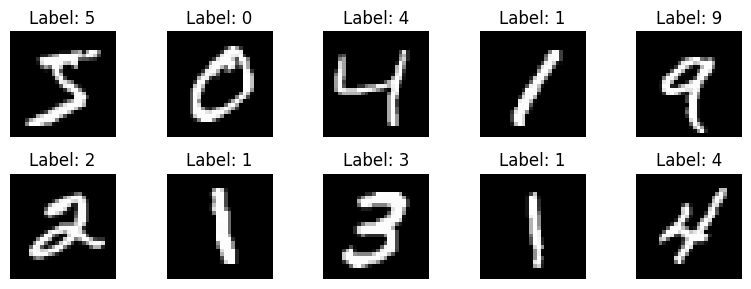

In [3]:
plt.figure(figsize=(8, 3))
for i in range(10):                      # change 10 -> autre nombre pour afficher plus/moins d'images
    plt.subplot(2, 5, i + 1)             # grille de 2 lignes x 5 colonnes
    plt.imshow(x_train[i], cmap='gray')  # cmap='gray' : affichage en niveaux de gris
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')                      # cache les axes
plt.tight_layout()
plt.show()

on identifie les chiffres affichés et on vérifie que chaque titre (`Label`) correspond bien au chiffre dessiné.(Le premier est un 5, puis 0, 4, 1, 9, 2, 1, 3, 1, 4.)

###  Questions : section 3
**1. Quelle commande change le nombre d'images affichées ?**
Il faut modifier `range(10)` (ex. `range(20)`) **et** adapter la grille `plt.subplot(lignes, colonnes, i+1)` pour qu'elle ait assez de cases (ex. `plt.subplot(4, 5, i+1)`).

**2. Que représente `cmap='gray'` ?**
C'est la **palette de couleurs** (colormap) : elle affiche les valeurs en niveaux de gris (0 = noir, 1 = blanc). Sans elle, matplotlib colorie l'image en vert/jaune.

**3. Utilité de cette étape ?**
Vérifier que les données sont **correctes** (bons labels, bonne forme, pas d'images vides) **avant** de perdre du temps à entraîner. Un modèle ne peut pas être meilleur que ses données (*garbage in, garbage out*).

## 4. Construction du modèle

In [4]:
model = Sequential([
    Input(shape=(28, 28)),                 # entrée : image 28x28
    Flatten(),                             # 28x28 -> vecteur de 784 valeurs
    Dense(128, activation='relu'),         # couche cachée : 128 neurones
    Dense(10, activation='softmax')        # sortie : 10 classes (chiffres 0 à 9)
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### Questions : section 4
**1. Combien de paramètres ?**
- Dense(128) : 784 × 128 poids + 128 biais = **100 480**
- Dense(10) : 128 × 10 poids + 10 biais = **1 290**
- Flatten : 0

Total = **101 770 paramètres** (vérifie avec `model.summary()`).

**2. Fonction d'activation de la couche de sortie ? Pourquoi ?**
**Softmax**. Elle transforme les 10 sorties en **probabilités** dont la somme vaut 1 (ex. 0.92 pour « 7 »). On prend la classe la plus probable avec `argmax`. C'est le bon choix pour une **classification multiclasse**.

**3. Différence ReLU / Softmax ?**
- **ReLU** : `max(0, x)`. Elle met les négatifs à 0. Utilisée dans les **couches cachées** (simple, rapide, évite le gradient qui disparaît).
- **Softmax** : transforme un vecteur en probabilités (somme = 1). Utilisée uniquement en **sortie** pour la classification multiclasse.

## 5. Compilation du modèle

In [5]:
model.compile(
    optimizer='adam',                          # ajuste les poids
    loss='sparse_categorical_crossentropy',    # labels = entiers (0..9), pas one-hot
    metrics=['accuracy']                       # précision, juste pour nous informer
)

### Questions : section 5
**1. Qu'est-ce qu'un optimiseur ?**
L'algorithme qui **met à jour les poids** pour diminuer la loss, en utilisant les gradients calculés par la rétropropagation (Adam, SGD, RMSprop...).

**2. Pourquoi une fonction de perte ?**
Pour **mesurer l'erreur** entre la prédiction et la vraie valeur avec un seul nombre. Sans elle, le modèle ne sait pas s'il s'améliore ni dans quel sens corriger.

**3. Que se passe-t-il si on change la fonction de perte ?**
Le modèle optimise un autre objectif. Si elle est **incompatible** avec les labels ou la sortie, on a des erreurs ou de mauvais résultats. Exemple : `sparse_categorical_crossentropy` demande des labels entiers ; avec des labels one-hot il faut `categorical_crossentropy`. Utiliser une loss de régression (MSE) en classification donne un apprentissage bien moins efficace.

**4. Conséquence d'un mauvais optimiseur ?**
Apprentissage **trop lent**, qui **diverge** (la loss explose) ou qui reste bloqué dans un mauvais minimum. Le choix du learning rate compte aussi énormément.

**5. Différence `loss` / `metrics` ?**
- **loss** : ce que le modèle **minimise** pendant l'entraînement (doit être dérivable).
- **metrics** : ce que **nous** regardons pour juger (accuracy), elle **ne sert pas** à entraîner.

## 6. Entraînement du modèle

In [6]:
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=32,
    validation_data=(x_test, y_test)
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9255 - loss: 0.2631 - val_accuracy: 0.9595 - val_loss: 0.1412
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9662 - loss: 0.1138 - val_accuracy: 0.9702 - val_loss: 0.0999
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9768 - loss: 0.0786 - val_accuracy: 0.9728 - val_loss: 0.0880
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9821 - loss: 0.0593 - val_accuracy: 0.9758 - val_loss: 0.0758
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9852 - loss: 0.0459 - val_accuracy: 0.9764 - val_loss: 0.0770


**observation :** la précision d'entraînement (`accuracy`) **augmente** à chaque époque ( 0.92 → 0.98). La précision de validation (`val_accuracy`) suit la même tendance ( 0.96 → 0.975) mais avec un petit écart.

### Questions : section 6
**1. Que représente une époque ?**
Un passage **complet** sur les 60 000 images d'entraînement. Avec `batch_size=32`, une époque = 60 000 / 32 = **1875 mises à jour** des poids.

**2. Pourquoi un jeu de validation ?**
Pour mesurer la performance sur des données **non utilisées pour apprendre**, et détecter le **surapprentissage** pendant l'entraînement.

**3. Et avec 50 époques ?**
L'accuracy d'entraînement monte presque à 100 %, mais la validation **stagne ou baisse** : le modèle **mémorise** au lieu de généraliser (*overfitting*). Le temps de calcul est aussi multiplié par 10.

> Remarque: dans ce TP, `x_test` sert à la fois de validation et de test final. En vrai projet, on utilise un **3ᵉ jeu séparé** pour le test final.

## 7. Évaluation du modèle

In [7]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")
ex1_test_acc = test_acc   # on garde pour le résumé final

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9764 - loss: 0.0770
Test accuracy: 0.9764
Test loss: 0.0770


###  Questions : section 7
**1. Précision finale ?**
0.9764

**2. Pourquoi test < entraînement ?**
Le modèle a **appris sur les données d'entraînement** (il les a vues et en a retenu des détails). Le test contient des images **jamais vues** : c'est la vraie capacité de généralisation, forcément un peu plus basse.

**3. Que faire en cas d'overfitting ?**
- Plus de données (ou *data augmentation*)
- **Dropout** (éteindre des neurones au hasard)
- Modèle plus simple (moins de couches/neurones)
- **Early stopping** (arrêter quand la validation ne s'améliore plus)
- Régularisation L1/L2
- Utiliser un CNN

## 8. Visualisation des performances


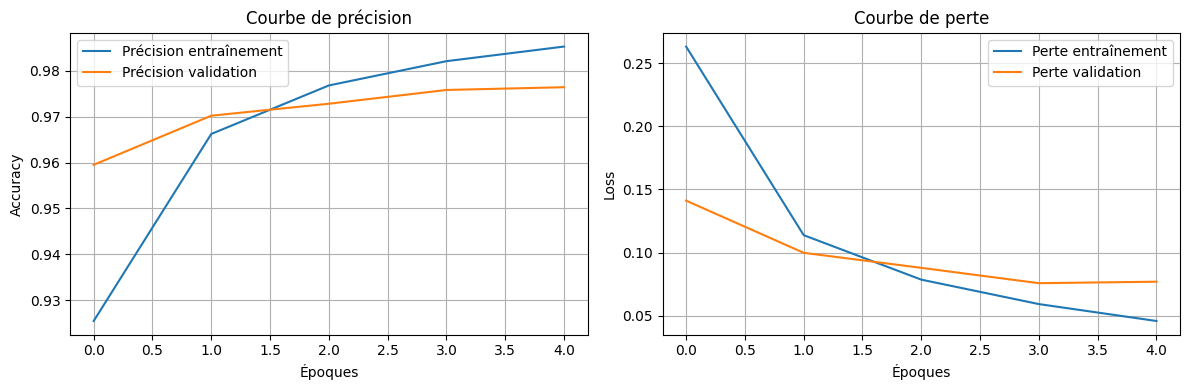

In [8]:
plt.figure(figsize=(12, 4))

# Courbe de précision
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Précision entraînement')
plt.plot(history.history['val_accuracy'], label='Précision validation')
plt.title('Courbe de précision')
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Courbe de perte
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Perte entraînement')
plt.plot(history.history['val_loss'], label='Perte validation')
plt.title('Courbe de perte')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Questions : section 8
**1. Que remarque-t-on ?**
La précision d'entraînement **monte**, la loss **descend**. La validation suit de près, avec un petit écart (le modèle apprend bien).

**2. Comment détecter visuellement un surapprentissage ?**
La courbe d'entraînement continue de s'améliorer, mais la courbe de validation **s'arrête de monter** (ou la loss de validation **remonte**). L'écart entre les deux courbes **grandit**.

**3. Quelle stratégie pour y remédier ?**
Dropout, early stopping, plus de données, data augmentation, modèle plus petit.

**4. Que faire si les deux courbes divergent ?**
C'est le signe d'overfitting : on **arrête plus tôt**, on ajoute de la **régularisation** (Dropout), on **simplifie** le modèle ou on **augmente** les données.

## 9. Prédictions et visualisation

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


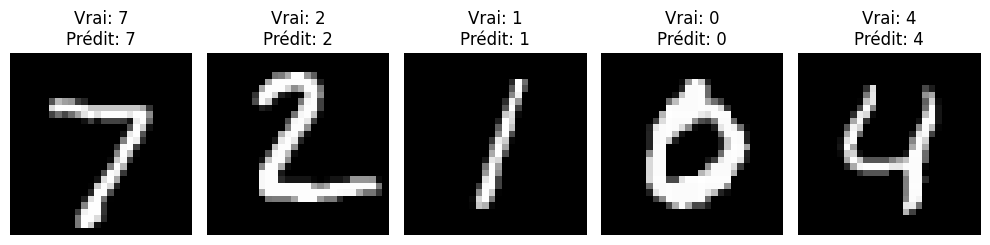

In [10]:
predictions = model.predict(x_test)   # tableau (10000, 10) : probabilités par classe

plt.figure(figsize=(10, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Vrai: {y_test[i]}\nPrédit: {np.argmax(predictions[i])}")
    plt.axis('off')
plt.tight_layout()
plt.show()

Nombre d'erreurs : 236 sur 10000


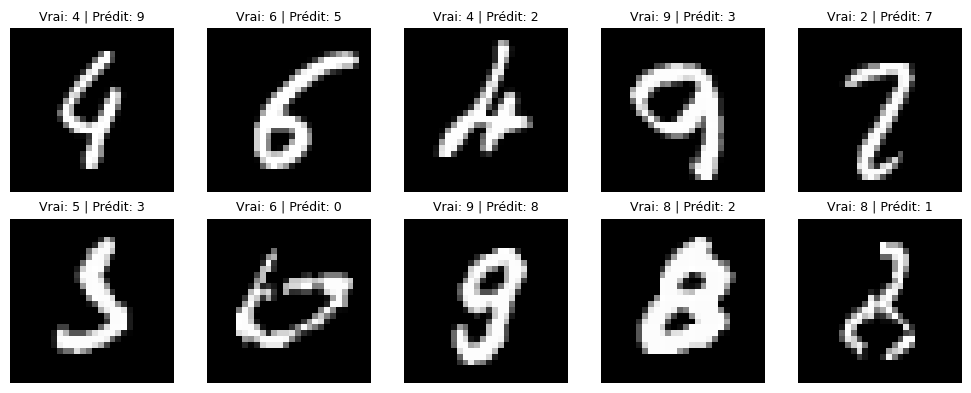

In [11]:
# afficher les images où le modèle SE TROMPE (pour répondre à la question 1)
y_pred_ex1 = np.argmax(predictions, axis=1)
erreurs = np.where(y_pred_ex1 != y_test)[0]
print(f"Nombre d'erreurs : {len(erreurs)} sur {len(y_test)}")

plt.figure(figsize=(10, 4))
for k, i in enumerate(erreurs[:10]):
    plt.subplot(2, 5, k + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Vrai: {y_test[i]} | Prédit: {y_pred_ex1[i]}", fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

### Questions : section 9
**1. Le modèle fait-il des erreurs ? Sur quelles images ?**
Oui, environ 2 à 2,5 % d'erreurs ( 236 images sur 10 000). Sur les 5 premières images il se trompe rarement . Les erreurs viennent surtout de chiffres **mal écrits ou ambigus** (4/9, 3/5, 7/1, 2/7).

**2. Comment expliquer une prédiction erronée ?**
Écriture inhabituelle, chiffre ressemblant à un autre, image un peu décalée ou mal centrée. Un réseau Dense **ne comprend pas la forme spatiale** : il voit juste 784 nombres sans voisinage.

**3. Quelle technique pour améliorer ?**
Un **CNN** (convolutions) qui exploite la structure 2D de l'image : il atteint ≈ 99 % sur MNIST. On peut aussi ajouter des couches, du Dropout, ou faire de la data augmentation.




---
#  EXERCICE 2


## Imports et chargement

In [12]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Pour la reproductibilité (résultats proches à chaque exécution)
tf.random.set_seed(42)
np.random.seed(42)

# Chargement du dataset
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

class_names = ['T-shirt', 'Pantalon', 'Pull', 'Robe', 'Manteau',
               'Sandale', 'Chemise', 'Basket', 'Sac', 'Bottine']

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## Étape 1 : Exploration du jeu de données
### A. Dimensions et types

In [13]:
print("Dimensions du train set :", X_train.shape)   # (60000, 28, 28)
print("Dimensions du test set :", X_test.shape)     # (10000, 28, 28)
print("Type des pixels :", X_train.dtype)           # uint8
print("Labels uniques :", np.unique(y_train))
print("Nombre d'images par classe :", np.bincount(y_train))

Dimensions du train set : (60000, 28, 28)
Dimensions du test set : (10000, 28, 28)
Type des pixels : uint8
Labels uniques : [0 1 2 3 4 5 6 7 8 9]
Nombre d'images par classe : [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


### B. Visualisation d'exemples

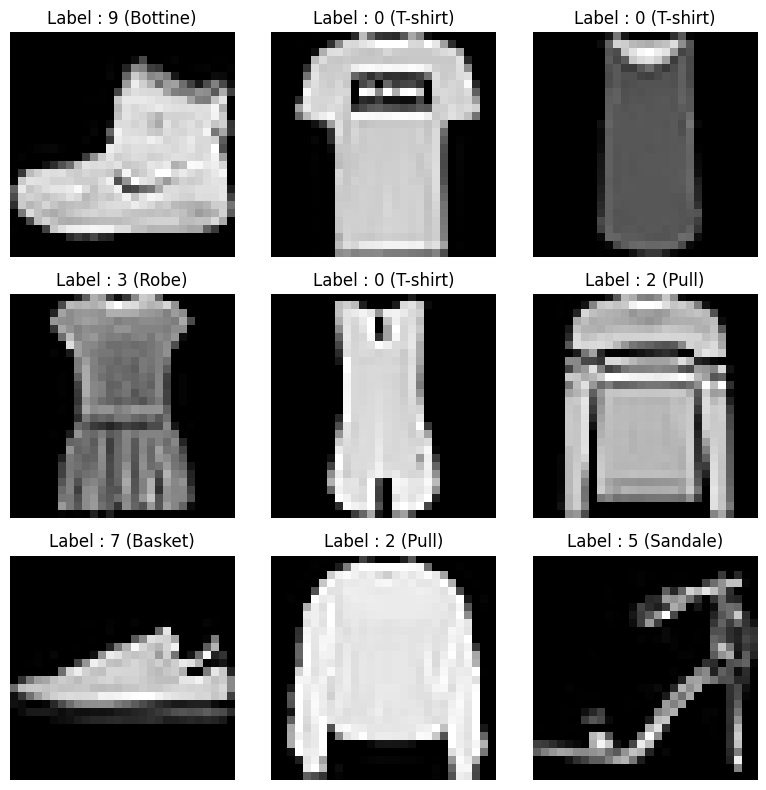

In [14]:
plt.figure(figsize=(8, 8))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label : {y_train[i]} ({class_names[y_train[i]]})")
    plt.axis('off')
plt.tight_layout()
plt.show()

**Question : Que remarque-t-on sur la nature des données et la taille des images ?**
- Ce sont des **images de vêtements**, en **niveaux de gris**, de taille **28×28** (petites et de faible résolution).
- Le dataset est **équilibré** : 6 000 images par classe.
- Les images sont centrées, avec peu de détails : certaines classes se **ressemblent beaucoup** (T-shirt / Chemise / Pull / Manteau), donc c'est plus dur que MNIST.
- Les pixels sont des `uint8` (0–255), à normaliser.

## Étape 2 : Prétraitement des données
Trois choses : **mise à l'échelle** (0–1), **conversion en float**, **encodage des labels** (one-hot).



In [15]:
from tensorflow.keras.utils import to_categorical

# Normalisation des pixels entre 0 et 1 (+ conversion en float32)
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Encodage one-hot des labels : 3 -> [0,0,0,1,0,0,0,0,0,0]
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print("Exemple de label :", y_train[0], "->", y_train_cat[0])
print("Pixels min/max :", X_train.min(), "/", X_train.max())

Exemple de label : 9 -> [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
Pixels min/max : 0.0 / 1.0


### Questions
**1. Pourquoi normaliser les images ?**
Pour mettre les pixels sur une petite échelle commune (0–1) : l'entraînement est plus **stable et plus rapide**, les gradients sont mieux calibrés. `float32` est aussi le type attendu par TensorFlow (et plus léger que `float64`).

**2. Importance du one-hot encoding ?**
Les classes sont des **catégories**, pas des quantités : « Robe = 3 » ne veut pas dire « 3 fois un T-shirt ». Le one-hot évite que le modèle croie à un **ordre** entre les classes, et correspond à la sortie `softmax` (un vecteur de 10 probabilités). Il est requis par `categorical_crossentropy`. *(Alternative : garder les labels entiers et utiliser `sparse_categorical_crossentropy`.)*

## Étape 3 : Création d'un modèle dense (ANN)

In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout

model_ann = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.2),                  # éteint 20% des neurones au hasard (anti-overfitting)
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model_ann.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

**Paramètres :** Dense(128) = 100 480 ; Dense(64) = 128×64+64 = 8 256 ; Dense(10) = 64×10+10 = 650 ; Dropout = 0. **Total = 109 386.**

**Dropout(0.2)** : pendant l'entraînement seulement, 20 % des neurones sont ignorés au hasard à chaque batch. Le réseau ne peut plus dépendre d'un seul neurone : il **généralise mieux**.

### Compilation et entraînement

In [17]:
model_ann.compile(
    optimizer='adam',
    loss='categorical_crossentropy',   # labels en one-hot
    metrics=['accuracy']
)

history_ann = model_ann.fit(
    X_train, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2      # 20% du train sert de validation (12 000 images)
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.7767 - loss: 0.6344 - val_accuracy: 0.8433 - val_loss: 0.4386
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8431 - loss: 0.4316 - val_accuracy: 0.8527 - val_loss: 0.3982
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8594 - loss: 0.3867 - val_accuracy: 0.8586 - val_loss: 0.3811
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8685 - loss: 0.3595 - val_accuracy: 0.8618 - val_loss: 0.3692
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8724 - loss: 0.3466 - val_accuracy: 0.8671 - val_loss: 0.3621
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8793 - loss: 0.3294 - val_accuracy: 0.8707 - val_loss: 0.3463
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8825 - loss: 0.3175 - val_accuracy: 0.8744 - val_loss: 0.3406
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8845 - loss: 0.3097 - val_accuracy: 0.

### Visualisation (précision et perte)

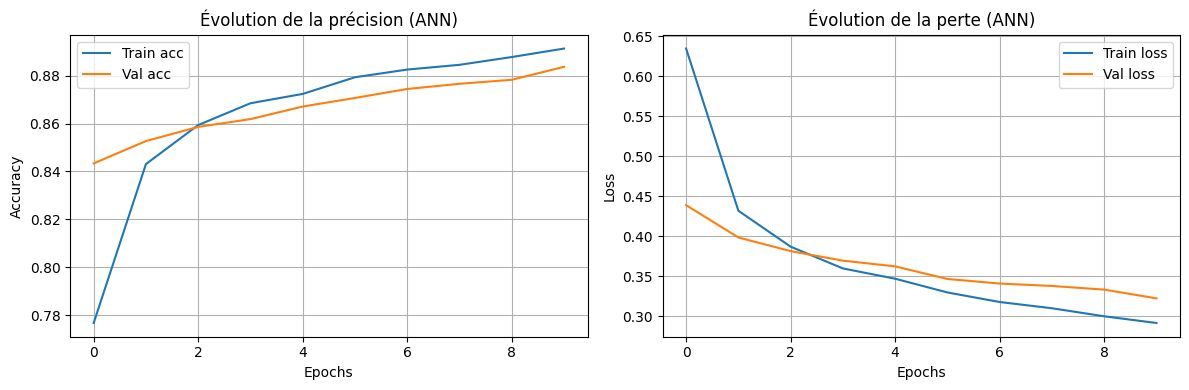

In [18]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_ann.history['accuracy'], label='Train acc')
plt.plot(history_ann.history['val_accuracy'], label='Val acc')
plt.legend()
plt.title('Évolution de la précision (ANN)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_ann.history['loss'], label='Train loss')
plt.plot(history_ann.history['val_loss'], label='Val loss')
plt.legend()
plt.title('Évolution de la perte (ANN)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True)

plt.tight_layout()
plt.show()

###  Questions
**1. Pourquoi ReLU ici ?**
- Simple et **rapide** à calculer : `max(0, x)`.
- Elle évite le problème du **gradient qui disparaît** (vanishing gradient) pour les valeurs positives.
- Elle introduit la **non-linéarité** nécessaire pour apprendre des formes complexes.
- C'est le choix par défaut dans les couches cachées.

**2. Différence `accuracy` / `val_accuracy` ?**
- `accuracy` : précision sur les données d'**entraînement** (celles que le modèle apprend).
- `val_accuracy` : précision sur les données de **validation** (20 % mis de côté, **non utilisées pour mettre à jour les poids**). C'est elle qui indique la vraie capacité de généralisation.

**3. Et avec 50 époques ?**
`accuracy` continue de monter (vers 95 %+) mais `val_accuracy` stagne vers ~89 % puis peut baisser, et `val_loss` **remonte** : c'est de l'**overfitting**. Solution : early stopping, plus de Dropout.

### Évaluation finale

In [19]:
test_loss, test_acc = model_ann.evaluate(X_test, y_test_cat)
print("Précision sur le test set :", test_acc)
acc_ann = test_acc

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8760 - loss: 0.3517
Précision sur le test set : 0.8759999871253967


Précision  environ **88 %.

## Étape 4 : Fonctions d'activation
**Objectif :** comparer **sigmoïde, tanh, ReLU et LeakyReLU** (même architecture, on change seulement l'activation).

sigmoid -> val_accuracy = 0.8612
tanh -> val_accuracy = 0.8703
relu -> val_accuracy = 0.8759
LeakyReLU -> val_accuracy = 0.8784


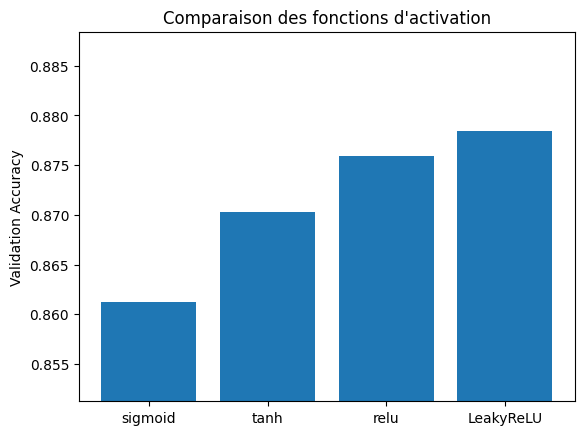

In [22]:
from tensorflow.keras.layers import LeakyReLU

activations = ['sigmoid', 'tanh', 'relu']
results = {}

for act in activations:
    model_act = Sequential([
        Input(shape=(28, 28)),
        Flatten(),
        Dense(128, activation=act),
        Dense(64, activation=act),
        Dense(10, activation='softmax')
    ])
    model_act.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    h = model_act.fit(X_train, y_train_cat, epochs=5, batch_size=128,
                      validation_split=0.2, verbose=0)
    results[act] = h.history['val_accuracy'][-1]
    print(f"{act} -> val_accuracy = {results[act]:.4f}")

# Leaky ReLU : c'est une COUCHE séparée (pas un string) donc on la met après un Dense sans activation
model_leaky = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128),
    LeakyReLU(0.1),
    Dense(64),
    LeakyReLU(0.1),
    Dense(10, activation='softmax')
])
model_leaky.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
h = model_leaky.fit(X_train, y_train_cat, epochs=5, batch_size=128,
                    validation_split=0.2, verbose=0)
results['LeakyReLU'] = h.history['val_accuracy'][-1]
print(f"LeakyReLU -> val_accuracy = {results['LeakyReLU']:.4f}")

plt.bar(results.keys(), results.values())
plt.title("Comparaison des fonctions d'activation")
plt.ylabel("Validation Accuracy")
plt.ylim(min(results.values()) - 0.01, max(results.values()) + 0.01)  # zoom pour voir les différences
plt.show()

###  Questions
**1. Quelle fonction donne les meilleurs résultats ?**
En général **ReLU et LeakyReLU** sont les meilleures (≈ 87–88 %), **tanh** est proche, **sigmoïde** est souvent un peu en dessous sur peu d'époques (elle apprend plus lentement). Les écarts sont petits : relancer peut changer le classement.
En général **ReLU et LeakyReLU** sont les meilleures (≈ 87–88 %), **tanh** est proche, **sigmoïde** est souvent un peu en dessous sur peu d'époques (elle apprend plus lentement). Les écarts sont petits : relancer peut changer le classement.

**2. Pourquoi sigmoïde et tanh sont moins utilisées dans les couches cachées ?**
Elles **saturent** : pour de grandes valeurs positives ou négatives, la pente est presque nulle → le gradient devient minuscule (**vanishing gradient**) → l'apprentissage devient lent dans les réseaux profonds. De plus, elles demandent des calculs d'exponentielle, plus coûteux que ReLU. La sigmoïde n'est pas centrée sur 0 (sortie entre 0 et 1).

**3. À quoi sert LeakyReLU ?**
ReLU met tous les négatifs à 0 : un neurone qui ne reçoit que des négatifs peut devenir **« mort »** (il n'apprend plus). LeakyReLU laisse passer une **petite pente** pour les négatifs (`0.1 × x`), donc le gradient n'est jamais exactement nul.

## Étape 5 : Modèle CNN
Un CNN exploite la **structure spatiale** de l'image (les pixels voisins sont liés).

- `Conv2D` : des petits filtres (3×3) qui glissent sur l'image pour détecter des motifs (bords, textures, formes).
- `MaxPooling2D((2,2))` : garde le max de chaque bloc 2×2 → image **2 fois plus petite**, garde l'essentiel.
- `Flatten` puis `Dense` : on classe à partir des motifs détectés.

**Forme des données :** une couche `Conv2D` attend (hauteur, largeur, **canaux**). Nos images n'ont pas de dimension canal → on fait un `reshape(-1, 28, 28, 1)`.

In [24]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D

# Ajout de la dimension "canal" : (60000, 28, 28) -> (60000, 28, 28, 1)
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

def make_cnn():
    m = Sequential([
        Input(shape=(28, 28, 1)),
        Conv2D(32, (3, 3), activation='relu'),   # 28x28 -> 26x26x32
        MaxPooling2D((2, 2)),                    # -> 13x13x32
        Conv2D(64, (3, 3), activation='relu'),   # -> 11x11x64
        MaxPooling2D((2, 2)),                    # -> 5x5x64
        Flatten(),                               # -> 1600
        Dense(128, activation='relu'),
        Dropout(0.3),
        Dense(10, activation='softmax')
    ])
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return m

cnn = make_cnn()
cnn.summary()

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_15 (Flatten)            │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

**Paramètres du CNN (vérifie avec le summary) :** Conv2D(32) = 3×3×1×32+32 = 320 ; Conv2D(64) = 3×3×32×64+64 = 18 496 ; Dense(128) = 1600×128+128 = 204 928 ; Dense(10) = 1 290. **Total = 225 034.** Les pooling et Flatten n'ont aucun paramètre.

### Entraînement

In [25]:
history_cnn = cnn.fit(
    X_train_cnn, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.7640 - loss: 0.6580 - val_accuracy: 0.8517 - val_loss: 0.4192
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8536 - loss: 0.4069 - val_accuracy: 0.8673 - val_loss: 0.3625
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8713 - loss: 0.3521 - val_accuracy: 0.8817 - val_loss: 0.3230
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8839 - loss: 0.3218 - val_accuracy: 0.8878 - val_loss: 0.3071
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8905 - loss: 0.2971 - val_accuracy: 0.8926 - val_loss: 0.2934
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8984 - loss: 0.2774 - val_accuracy: 0.8957 - val_loss: 0.2831
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9051 - loss: 0.2617 - val_accuracy: 0.8993 - val_loss: 0.2732
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9092 - loss: 0.2473 - val_accuracy: 0

### Évaluation

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9029 - loss: 0.2687
Précision CNN sur test set : 0.902899980545044


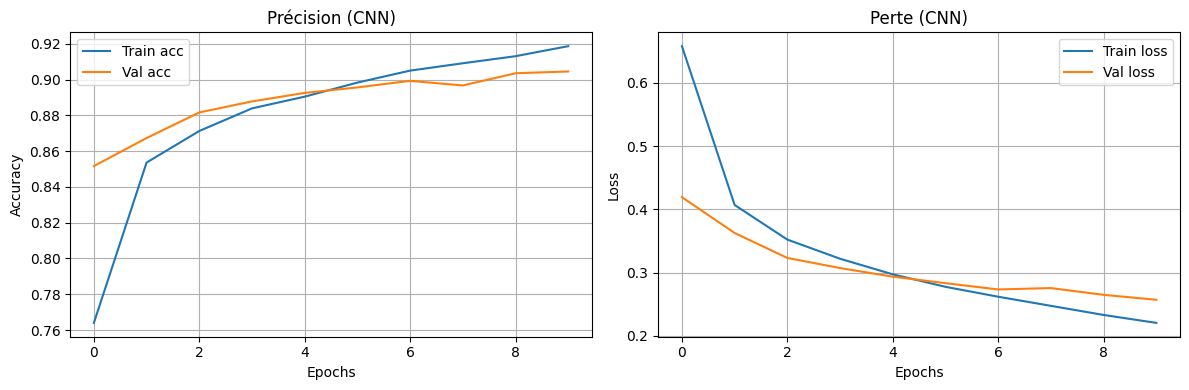

In [26]:
test_loss, test_acc = cnn.evaluate(X_test_cnn, y_test_cat)
print("Précision CNN sur test set :", test_acc)
acc_cnn = test_acc

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_cnn.history['accuracy'], label='Train acc')
plt.plot(history_cnn.history['val_accuracy'], label='Val acc')
plt.title('Précision (CNN)'); plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_cnn.history['loss'], label='Train loss')
plt.plot(history_cnn.history['val_loss'], label='Val loss')
plt.title('Perte (CNN)'); plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend(); plt.grid(True)
plt.tight_layout()
plt.show()

Précision environ **91 % à 92,5 %**

### Questions
**1. Différence ANN / CNN ?**
- **ANN (Dense)** : chaque pixel est relié à chaque neurone après `Flatten`. On **perd la structure 2D**, et on a beaucoup de paramètres.
- **CNN** : utilise des **filtres convolutifs** qui regardent des petites zones locales de l'image et **partagent les mêmes poids** sur toute l'image. Il garde la structure spatiale.

**2. Pourquoi le CNN est généralement meilleur ?**
Il détecte automatiquement des **motifs locaux** (bords, coins, textures), puis les combine en formes plus complexes de couche en couche. Il est aussi **moins sensible à la position** de l'objet et utilise le **partage de poids**, donc plus efficace pour les images.

**3. Rôle du Pooling ?**
Il **réduit la taille** des cartes de caractéristiques (donc moins de calculs et de paramètres), garde l'information la plus importante (max), apporte une petite **invariance aux petits décalages** et aide à limiter l'overfitting.

## Étape 6 : Visualisation des performances (matrice de confusion)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


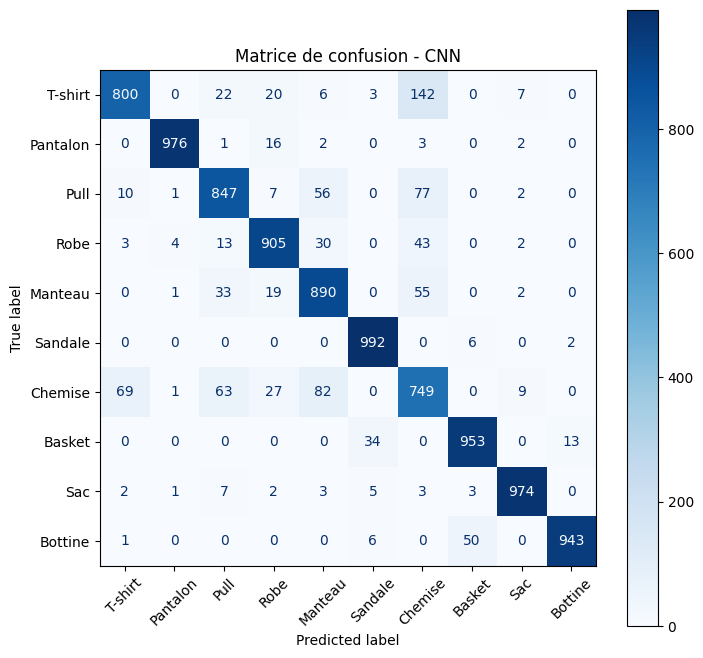

Vrai 'T-shirt' prédit 'Chemise' : 142 fois
Vrai 'Chemise' prédit 'Manteau' : 82 fois
Vrai 'Pull' prédit 'Chemise' : 77 fois


In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = np.argmax(cnn.predict(X_test_cnn), axis=1)

fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=class_names, cmap="Blues", ax=ax, xticks_rotation=45
)
plt.title("Matrice de confusion - CNN")
plt.show()

# Les 3 confusions les plus fréquentes (on met la diagonale à 0 pour ne garder que les erreurs)
cm = confusion_matrix(y_test, y_pred)
cm_err = cm.copy()
np.fill_diagonal(cm_err, 0)
top = np.dstack(np.unravel_index(np.argsort(cm_err.ravel())[::-1][:3], cm_err.shape))[0]
for vrai, predit in top:
    print(f"Vrai '{class_names[vrai]}' prédit '{class_names[predit]}' : {cm_err[vrai, predit]} fois")

##Questions
**1. Quelles classes sont le plus souvent confondues ?**
Typiquement **Chemise (6) ↔ T-shirt (0)**, puis **Chemise ↔ Pull (2)** et **Pull ↔ Manteau (4)**. Ce sont des vêtements du haut avec des formes très proches en 28×28. Les classes faciles : Pantalon, Sac, Basket, Bottine.

**2. Comment réduire ces erreurs ?**
- Un CNN **plus profond** (plus de filtres, BatchNormalization)
- **Data augmentation**
- Entraîner plus longtemps avec early stopping
- Ajuster les hyperparamètres (learning rate, taille de batch)
- **Transfer learning** (modèle pré-entraîné) ou ensemble de modèles

## Étape 7 : Data Augmentation
On génère de **nouvelles images** à partir des existantes (petites rotations, zoom, retournement) pour que le modèle voie plus de variété.

Je repars d'un **nouveau CNN** (`make_cnn()`) pour comparer équitablement avec le CNN précédent (sinon on cumulerait 20 époques).

In [28]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,     # rotation aléatoire jusqu'à 10 degrés
    zoom_range=0.1,        # zoom aléatoire de 10%
    horizontal_flip=True   # retournement gauche-droite
)
datagen.fit(X_train_cnn)

cnn_aug = make_cnn()
history_aug = cnn_aug.fit(
    datagen.flow(X_train_cnn, y_train_cat, batch_size=128),
    epochs=10,
    validation_data=(X_test_cnn, y_test_cat)
)

test_loss, acc_aug = cnn_aug.evaluate(X_test_cnn, y_test_cat)
print("Précision CNN + Data Augmentation :", acc_aug)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 24s 46ms/step - accuracy: 0.7466 - loss: 0.6934 - val_accuracy: 0.8371 - val_loss: 0.4401
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 17s 36ms/step - accuracy: 0.8267 - loss: 0.4668 - val_accuracy: 0.8523 - val_loss: 0.4025
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 17s 35ms/step - accuracy: 0.8475 - loss: 0.4124 - val_accuracy: 0.8617 - val_loss: 0.3677
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 17s 36ms/step - accuracy: 0.8608 - loss: 0.3797 - val_accuracy: 0.8748 - val_loss: 0.3405
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 35ms/step - accuracy: 0.8673 - loss: 0.3608 - val_accuracy: 0.8733 - val_loss: 0.3472
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 34ms/step - accuracy: 0.8728 - loss: 0.3458 - val_accuracy: 0.8843 - val_loss: 0.3124
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 39ms/step - accuracy: 0.8775 - loss: 0.3310 - val_accuracy: 0.8930 - val_loss: 0.3000
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 21s 44ms/step - accuracy: 0.8830 - loss: 0.3198 - 


### Questions
**1. Intérêt de la Data Augmentation ?**
Augmenter artificiellement la **quantité et la variété** des données → le modèle **généralise mieux**, devient plus robuste aux petites variations et **réduit l'overfitting**, sans collecter de nouvelles images.

**2. Quelles transformations semblent les plus efficaces pour ce dataset ?**
- **Retournement horizontal** : très pertinent (un T-shirt retourné reste un T-shirt, une basket aussi).
- **Petite rotation / petit zoom / petit décalage** : réalistes.
- À éviter : le **retournement vertical** (un vêtement à l'envers n'est pas réaliste) et les grosses rotations.

L'amélioration reste souvent **modeste** (parfois ±0,5 %) avec 10 époques seulement ; l'effet est plus net avec plus d'époques.

## Résumé des résultats

Ex1 - MNIST (Dense)                 : 0.9764  (97.64 %)
Ex2 - Fashion ANN                   : 0.8760  (87.60 %)
Ex2 - Fashion CNN                   : 0.9029  (90.29 %)
Ex2 - Fashion CNN + augmentation    : 0.8977  (89.77 %)


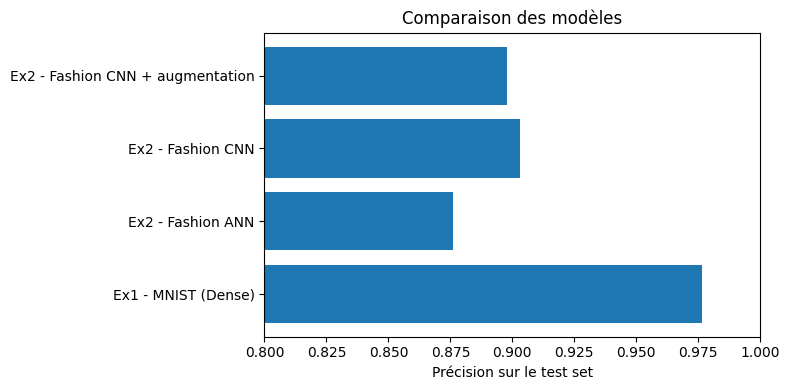

In [29]:
resume = {
    "Ex1 - MNIST (Dense)": ex1_test_acc,
    "Ex2 - Fashion ANN": acc_ann,
    "Ex2 - Fashion CNN": acc_cnn,
    "Ex2 - Fashion CNN + augmentation": acc_aug,
}
for nom, a in resume.items():
    print(f"{nom:35s} : {a:.4f}  ({a*100:.2f} %)")

plt.figure(figsize=(8, 4))
plt.barh(list(resume.keys()), list(resume.values()))
plt.xlim(0.8, 1.0)
plt.xlabel("Précision sur le test set")
plt.title("Comparaison des modèles")
plt.tight_layout()
plt.show()